Python: d:\Crypto_project\.venv\Scripts\python.exe
BTCUSDT: 2,321,280 nến 1m → 464,256 nến 5m; gap: 0
Open đầu/cuối: 2021-01-01 00:00:00+00:00 2025-05-31 23:55:00+00:00
Số signal: {'sig_long': 152, 'sig_short': 150}


,atr_short,atr_long,delta,vol_ratio,jump_ratio_signed,vwpd,ready,sig_long,sig_short
timestamp,,,,,,,,,
2025-05-31 23:35:00+00:00,90.079,95.197333,1.1,0.946234,0.011555,0.000621,True,False,False
2025-05-31 23:40:00+00:00,89.813,94.980000,-9.9,0.945599,-0.104232,-0.005670,True,False,False
2025-05-31 23:45:00+00:00,89.368,94.118000,8.7,0.949531,0.092437,0.004665,True,False,False
2025-05-31 23:50:00+00:00,88.738,94.245333,-53.7,0.941564,-0.569789,-0.033296,True,False,False
2025-05-31 23:55:00+00:00,86.684,94.004667,-13.8,0.922124,-0.146801,-0.011432,True,False,False


decision_reason
flat           428560
hold            35288
sl                133
entry_long        108
entry_short        96
tp                 46
max_hold           25
Name: count, dtype: int64
Fees and fill-price slippage included; funding NOT included


,value,reason
annualized_simple_return,0.130654,
average_closed_holding_duration,0 days 14:29:54.117647058,
average_daily_margin_turnover_on_initial,0.253341,
average_net_pnl_per_closed_trade_vnd,28285506.827858,
closed_trade_count,204,
elapsed_years,4.416438,
gross_profit_vnd,7812174709.716348,
max_drawdown_pct_initial,0.201153,
max_drawdown_vnd,2011526524.964855,
net_profit_vnd,5770243392.882986,


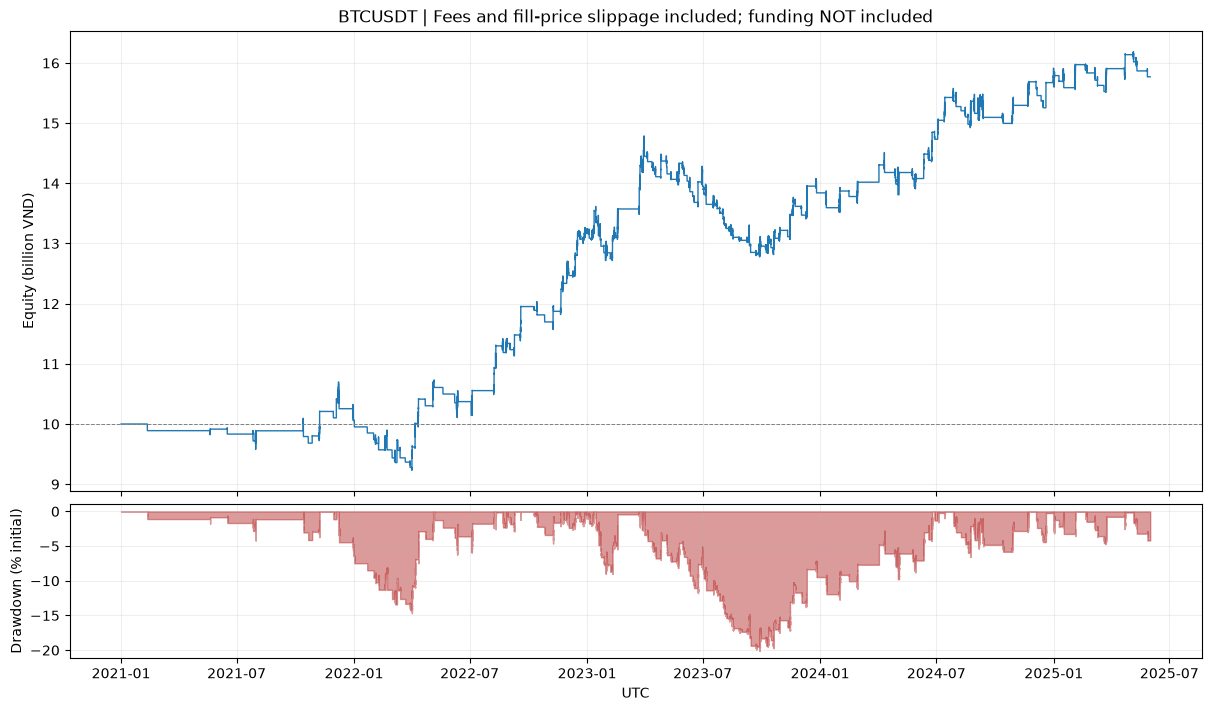

In [11]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "bt_crypto.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Mở notebook từ D:/Crypto_project hoặc thư mục research")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from bt_crypto import BacktestConfig, backtest
from research.alpha_helpers import load_bars, features_by_segment, build_targets, run_grid

# Baseline alpha38_1: VWPD trên BTC 5m; tham số ban đầu chưa tối ưu cho BTC.
ASSET = "BTCUSDT"
TIMEFRAME = "5min"
START_UTC = "2021-01-01"
END_UTC = "2025-06-01"  # Exclusive; None = hết dữ liệu local.
PARAMS = {
    "atr_short": 100,       # SMA true range ngắn
    "atr_long": 150,        # SMA true range dài
    "vwpd_threshold": 0.5,
    "tp": 0.04,            # 4% từ actual entry fill
    "sl": 0.01,            # 1% từ actual entry fill
    "max_hold": 500,       # Số nến quan sát, gồm nến entry
}
INITIAL_CAPITAL_VND = 10_000_000_000
FIXED_MARGIN_BUDGET_VND = 10_000_000_000
LEVERAGE = 1.0
FX_VND_PER_USDT = 25_000.0  # Giả định cố định
SLIPPAGE_BPS = 1.0
# Fee mặc định 0,05% mỗi chiều; chưa có funding.
assert 0 < PARAMS["atr_short"] < PARAMS["atr_long"]
assert PARAMS["vwpd_threshold"] >= 0 and PARAMS["max_hold"] > 0
assert 0 < PARAMS["sl"] < 1 and PARAMS["tp"] > 0
assert 0 <= SLIPPAGE_BPS < 10000

def entry_conditions(features, p):
    # Tín hiệu tại Close; không có giới hạn giờ giao dịch.
    threshold = p["vwpd_threshold"]
    return (features.ready & features.vwpd.gt(threshold),
            features.ready & features.vwpd.lt(-threshold))

def calculate_vwpd_features(block, p):
    f = pd.DataFrame(index=block.index)
    previous_close = block.close.shift(1)
    tr = pd.concat([block.high - block.low, (block.high - previous_close).abs(),
                    (block.low - previous_close).abs()], axis=1).max(axis=1)
    f["atr_short"] = tr.rolling(p["atr_short"], min_periods=p["atr_short"]).mean()
    f["atr_long"] = tr.rolling(p["atr_long"], min_periods=p["atr_long"]).mean()
    f["delta"] = block.close.diff()
    denominator = f.atr_long.where(f.atr_long > 0)
    f["vol_ratio"] = f.atr_short / denominator
    f["jump_ratio_signed"] = f.delta / denominator
    # VWPD có dấu khi volatility đang nén; không thêm volume hoặc giờ giao dịch.
    f["vwpd"] = (f.jump_ratio_signed * (1 - f.vol_ratio)).where(f.vol_ratio < 1, 0.0)
    f["ready"] = np.isfinite(f[["atr_short", "atr_long", "delta", "vol_ratio", "jump_ratio_signed"]]).all(axis=1)
    f["sig_long"], f["sig_short"] = entry_conditions(f, p)
    return f

# Load nến hoàn chỉnh; reset feature windows sau gap.
df = load_bars(ASSET, START_UTC, END_UTC, TIMEFRAME)
features = features_by_segment(df, TIMEFRAME, calculate_vwpd_features, PARAMS)
print("Số signal:", features[["sig_long", "sig_short"]].sum().to_dict())
display(features.tail())

# Signal Close → fill next Open; TP/SL neo vào actual fill, kiểm tra khi đóng nến.
position_series, expected_position, expected_entry_fill, decision_reason = build_targets(
    df, features, PARAMS, SLIPPAGE_BPS)
print(decision_reason.value_counts())
config = BacktestConfig(
    asset=ASSET, timeframe=TIMEFRAME, timestamp_label="open", contract_type="linear_usdt",
    initial_capital_vnd=INITIAL_CAPITAL_VND, fixed_margin_budget_vnd=FIXED_MARGIN_BUDGET_VND,
    leverage=LEVERAGE, fx_vnd_per_usdt=FX_VND_PER_USDT, slippage_bps=SLIPPAGE_BPS,
)
result = backtest(ohlcv=df, target_position=position_series, config=config)
np.testing.assert_array_equal(expected_position.to_numpy(), result.ledger.position.to_numpy())
np.testing.assert_allclose(expected_entry_fill.to_numpy(), result.ledger.entry_fill_price.to_numpy(), equal_nan=True)
np.testing.assert_allclose(result.trades.net_pnl_vnd.sum(), result.metrics["net_profit_vnd"], rtol=1e-10, atol=0.05)
print(result.diagnostics["cost_scope"])
display(result.summary())
result.plot();

In [10]:
# GRID SEARCH — chạy cell backtest trước để có data, alpha functions và config.
# Khoảng in-sample UTC: START inclusive, END exclusive; phải nằm trong df đã load.
GRID_START_UTC = "2021-01-01"
GRID_END_UTC = "2025-06-01"
WORKERS = 8  # Số luồng CPU; chỉnh tùy máy.
BATCH_SIZE = 256
GRID = {
    "atr_short": [20, 25,30,50,80,100,200],
    "atr_long": [20,30,60,100,150],
    "vwpd_threshold": [0.15,0.2,0.25, 0.3,0.35,0.4,0.5,0.6],
    "tp": [0.02,0.03, 0.04],
    "sl": [0.01,0.015, 0.02,0.025,0.03],
    "max_hold": [200,300,500,1000],
}


# Chỉ ghép ATR ngắn với ATR dài lớn hơn; lưu một CSV không xếp hạng.
grid_results = run_grid(
    df, config, GRID, start=GRID_START_UTC, end=GRID_END_UTC,
    calculate_features=calculate_vwpd_features, entry_conditions=entry_conditions,
    feature_keys=("atr_short", "atr_long"), signal_keys=("vwpd_threshold",),
    valid_combo=lambda p: 0 < p["atr_short"] < p["atr_long"] and p["vwpd_threshold"] >= 0,
    workers=WORKERS, batch_size=BATCH_SIZE,
    save_dir=ROOT / "research" / "grid_results", filename_prefix="alpha38_grid",
)
display(grid_results.head(30))

Các cặp ATR hợp lệ: [(20, 30), (20, 60), (20, 100), (20, 150), (25, 30), (25, 60), (25, 100), (25, 150), (30, 60), (30, 100), (30, 150), (50, 60), (50, 100), (50, 150), (80, 100), (80, 150), (100, 150)]
Grid IS: [2021-01-01 00:00:00+00:00, 2025-06-01 00:00:00+00:00) | 464,256 nến | 8,160 cấu hình
Bắt đầu flat, features warmup trong khoảng IS; funding chưa bao gồm.
Numba biên dịch ở lần chạy đầu; sau scan nên chạy lại cấu hình chọn bằng bt_crypto.
Nhóm 1/136 | 60/8160 cấu hình | 0.1s
Nhóm 2/136 | 120/8160 cấu hình | 0.2s
Nhóm 3/136 | 180/8160 cấu hình | 0.3s
Nhóm 4/136 | 240/8160 cấu hình | 0.4s
Nhóm 5/136 | 300/8160 cấu hình | 0.5s
Nhóm 6/136 | 360/8160 cấu hình | 0.6s
Nhóm 7/136 | 420/8160 cấu hình | 0.6s
Nhóm 8/136 | 480/8160 cấu hình | 0.7s
Nhóm 9/136 | 540/8160 cấu hình | 1.0s
Nhóm 10/136 | 600/8160 cấu hình | 1.1s
Nhóm 11/136 | 660/8160 cấu hình | 1.2s
Nhóm 12/136 | 720/8160 cấu hình | 1.2s
Nhóm 13/136 | 780/8160 cấu hình | 1.3s
Nhóm 14/136 | 840/8160 cấu hình | 1.4s
Nhóm 15/136 |

,atr_short,atr_long,vwpd_threshold,tp,sl,max_hold,sharpe,mdd_pct_initial,annualized_simple_return,closed_trades
0,20,30,0.15,0.02,0.010,200,-2.917094,4.331956,-0.925198,2668
1,20,30,0.15,0.02,0.010,300,-2.337397,3.651260,-0.769593,2511
2,20,30,0.15,0.02,0.010,500,-2.178873,3.420354,-0.716445,2387
3,20,30,0.15,0.02,0.010,1000,-2.224793,3.487415,-0.731629,2329
4,20,30,0.15,0.02,0.015,200,-2.550424,4.232080,-0.899482,2397
5,20,30,0.15,0.02,0.015,300,-1.796585,3.134108,-0.656412,2194
6,20,30,0.15,0.02,0.015,500,-1.894543,3.307988,-0.696926,2047
7,20,30,0.15,0.02,0.015,1000,-1.881042,3.323352,-0.695740,1967
8,20,30,0.15,0.02,0.020,200,-2.118920,3.949154,-0.813661,2239
9,20,30,0.15,0.02,0.020,300,-1.672938,3.238530,-0.667782,2012


Đã lưu: d:\Crypto_project\research\grid_results\alpha38_grid_20261113_043133_375076.csv
